# Tiamat — Análise exploratória de partidas de Go (lance 40)

Este notebook explora os 24 atributos tabulares provenientes de SGFs do Joe’s Go Database. Não realiza treinamento de modelos, seleção supervisionada ou pré-processamento ajustado à base inteira. A análise exploratória com o target usa somente `split == "train"`; validação e teste permanecem reservados.

> **Método:** As observações são partidas, não jogadas. As posições são reconstruídas até o lance 40. Os ranks seguem uma codificação definida no projeto (`x k→-x`, `x d→x`, `x p→x+6`), que não deve ser interpretada como medida física universal de habilidade, pois é uma ideia sobre como se comporta o nível de diferentes jogadores de GO em uma classificação universal.

**Fonte dos dados:** Joe's Go Database — https://www.pjreddie.com/projects/jgdb/. O `.zip` foi coletado no dia 12 de setembro e extraído com o 7-zip. 

## 1. Bibliotecas e carregamento

Execute primeiro esta célula, que vai realizar a importação das bibliotecas e extração dos arquivos `.csv`. Ajuste `CAMINHOS` caso sua estrutura de pastas seja diferente.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEED = 210906
CAMINHOS = [
    Path("data/piloto_final/lance_040.csv"),
    Path("data/piloto_corrigido/lance_040.csv"),
    Path("data/piloto/lance_040.csv"),
    Path("lance_040.csv"),
]
caminho = next((p for p in CAMINHOS if p.exists()), None)
if caminho is None:
    raise FileNotFoundError("Coloque lance_040.csv em uma das pastas listadas em CAMINHOS.")
base = pd.read_csv(caminho)
print(f"Arquivo: {caminho} | dimensões: {base.shape}")
print("Divisões encontradas:", base["split"].value_counts().to_dict())

# A partir desta linha, EDA somente com treinamento.
train = base.loc[base["split"].eq("train")].copy()
print("Linhas de treinamento:", len(train))

Arquivo: data\piloto_final\lance_040.csv | dimensões: (5156, 34)
Divisões encontradas: {'train': 4612, 'test': 274, 'val': 270}
Linhas de treinamento: 4612


## 2. Integridade e definição das variáveis

Antes dos gráficos, a célula abaixo verifica se a estrutura é compatível com o experimento e separa claramente os atributos do target.

In [2]:
ATRIBUTOS = [
    "rank_b", "rank_w", "komi", "handicap",
    "maior_grupo_b", "maior_grupo_w",
    "liberdades_maior_grupo_b", "liberdades_maior_grupo_w",
    "pedras_em_jogo_b", "pedras_em_jogo_w",
    "pedras_capturadas_por_b", "pedras_capturadas_por_w",
    "distancia_media_tengen_b", "distancia_media_tengen_w",
    "quantidade_grupos_b", "quantidade_grupos_w",
    "tamanho_medio_grupos_b", "tamanho_medio_grupos_w",
    "liberdades_medias_grupos_b", "liberdades_medias_grupos_w",
    "grupos_em_atari_b", "grupos_em_atari_w",
    "pedras_em_atari_b", "pedras_em_atari_w",
]
TARGET = "vencedor"

assert len(ATRIBUTOS) == 24
assert set(ATRIBUTOS + [TARGET, "split", "game_id"]).issubset(train.columns)
assert train["lance"].eq(40).all(), "Há linhas de outros estágios!"
assert train["game_id"].is_unique, "Há identificadores repetidos no treinamento!"
assert train[TARGET].isin(["B", "W"]).all()
assert all(pd.api.types.is_numeric_dtype(train[c]) for c in ATRIBUTOS)

print("Linhas:", len(train), "| atributos:", len(ATRIBUTOS))
print("Hashes duplicados:", train["hash_sgf"].duplicated().sum())
print("Valores ausentes por atributo:")
print(train[ATRIBUTOS].isna().sum().sort_values(ascending=False).to_string())

Linhas: 4612 | atributos: 24
Hashes duplicados: 0
Valores ausentes por atributo:
komi                          65
handicap                       2
rank_w                         0
rank_b                         0
maior_grupo_b                  0
maior_grupo_w                  0
liberdades_maior_grupo_b       0
liberdades_maior_grupo_w       0
pedras_em_jogo_b               0
pedras_em_jogo_w               0
pedras_capturadas_por_b        0
pedras_capturadas_por_w        0
distancia_media_tengen_b       0
distancia_media_tengen_w       0
quantidade_grupos_b            0
quantidade_grupos_w            0
tamanho_medio_grupos_b         0
tamanho_medio_grupos_w         0
liberdades_medias_grupos_b     0
liberdades_medias_grupos_w     0
grupos_em_atari_b              0
grupos_em_atari_w              0
pedras_em_atari_b              0
pedras_em_atari_w              0


### Interpretação do output

Os valores ausentes são de komi e handicap. O komi é possível de se encontrar sabendo a quantidade de capturas, territórios cercados, e pontuação final de cada jogador ou sua diferença, o handicap se é possível visualizar nas jogadas inicias do arquivo, pois nas primeiras jogadas se tem as posições onde as peças de handicap ficam, sabendo quantas são se tem o handicap. Elas podem ser tratadas, mas a principio irei retirar essas partidas pois se tem uma grande quantidade de jogos.


## 3. Distribuição do vencedor

O equilíbrio das classes vão influenciar a escolha das métricas e a interpretação de uma baseline ingênua. Na célula abaixo é realizado a impressão de quantidade de vitórias de cada com sua respectiva porcentagem de vitória em conjunto com o plot de um gráfico de barras com a quantidade de vitórias para cada cor.

          partidas  percentual
vencedor                      
B             2271    49.24111
W             2341    50.75889


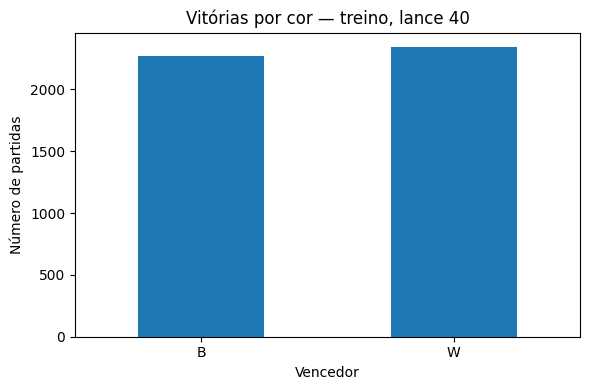

In [3]:
contagem = train[TARGET].value_counts().reindex(["B", "W"], fill_value=0)
print(pd.DataFrame({"partidas": contagem, "percentual": 100 * contagem / contagem.sum()}))
fig, ax = plt.subplots(figsize=(6, 4))
contagem.plot.bar(ax=ax)
ax.set(xlabel="Vencedor", ylabel="Número de partidas", title="Vitórias por cor — treino, lance 40")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Interpretação dos outputs

Como os dados estão próximos a uma distribuição de 50/50 entre vitórias de pretos e brancos, o problema se trata de classificação de targets balanceados.


## 4. Distribuições dos atributos iniciais

Não inferimos causalidade a partir destas distribuições. O intuito desta seção é identificar frequência de handicap, dispersão dos ranks e variabilidade do komi. Onde eles serão plotados em um histograma, um `describe` dos dados e o print dos handicap na célula abaixo.

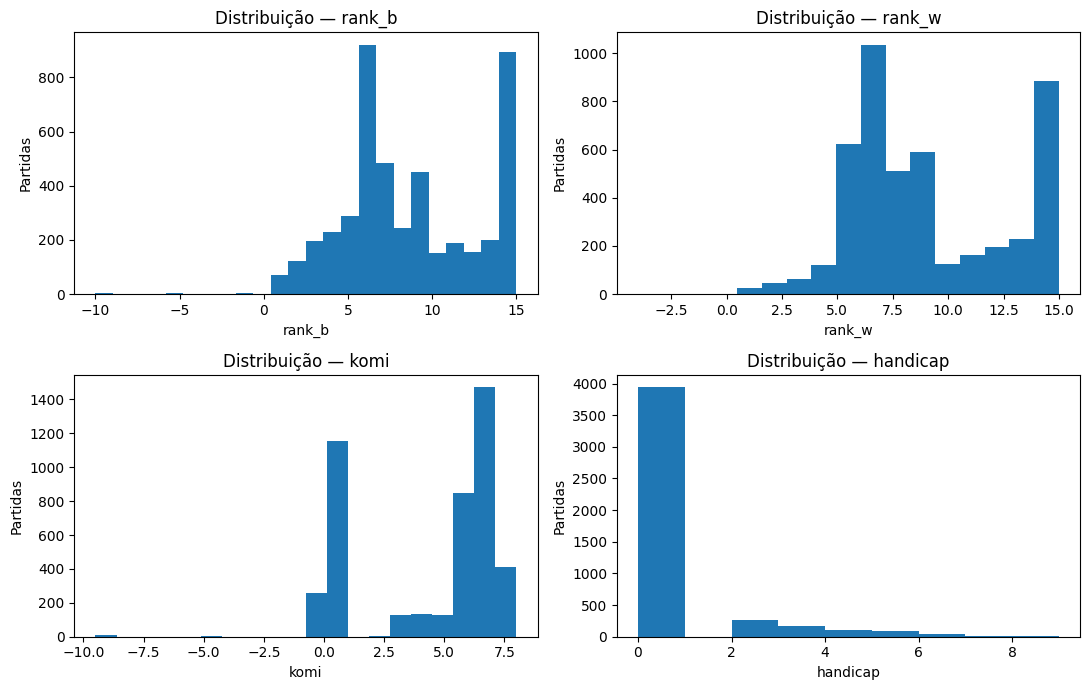

           count      mean       std   min  25%  50%   75%   max
rank_b    4612.0  8.533174  4.081153 -10.0  6.0  7.0  12.0  15.0
rank_w    4612.0  9.219861  3.490392  -4.0  7.0  8.0  12.0  15.0
komi      4547.0  4.236859  2.830110  -9.5  0.5  5.5   6.5   8.0
handicap  4610.0  0.482430  1.290104   0.0  0.0  0.0   0.0   9.0

Handicap (com ausentes):
handicap
0.0    3939
2.0     257
3.0     170
4.0     104
5.0      83
6.0      45
7.0       4
8.0       1
9.0       7
NaN       2


In [4]:
colunas = ["rank_b", "rank_w", "komi", "handicap"]
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axs.flat, colunas):
    dados = train[c].dropna()
    ax.hist(dados, bins=min(25, max(1, dados.nunique())), edgecolor="none")
    ax.set(xlabel=c, ylabel="Partidas", title=f"Distribuição — {c}")
plt.tight_layout()
plt.show()
print(train[colunas].describe().T.to_string())
print("\nHandicap (com ausentes):")
print(train["handicap"].value_counts(dropna=False).sort_index().to_string())


### Interpretação dos outputs

Para os ranks, é possível analisar que os jogadores de pretas tem em média, um rank menor que os jogadores de brancas isso ocorre pois, as pedras pretas são utilizadas pelo jogador com nível menor, pela vantagem de se jogar primeiro em um tabuleiro com casas finitas. O handicap é um tipo de dado desbalanceado pela presença majoritária em não se ter handicap. O komi se tem valores anormais para as regras usuais de GO, conhecidas por, pois se tem komi diferentes de 0,5 em que se é utilizado com se joga com handicap, e 6,5 quando não se joga com komi, o que poderia render uma analise mais aprofundada sobre o jogo e as partidas com komi diferentes.  


## 5. Atributos posicionais

O lance 40 é relativamente precoce: por isso, atributos como capturas podem concentrar muitos valores zero. Vamos verificar essa hipótese, onde na célula abaixo é plotado histogramas de atributos posicionais.

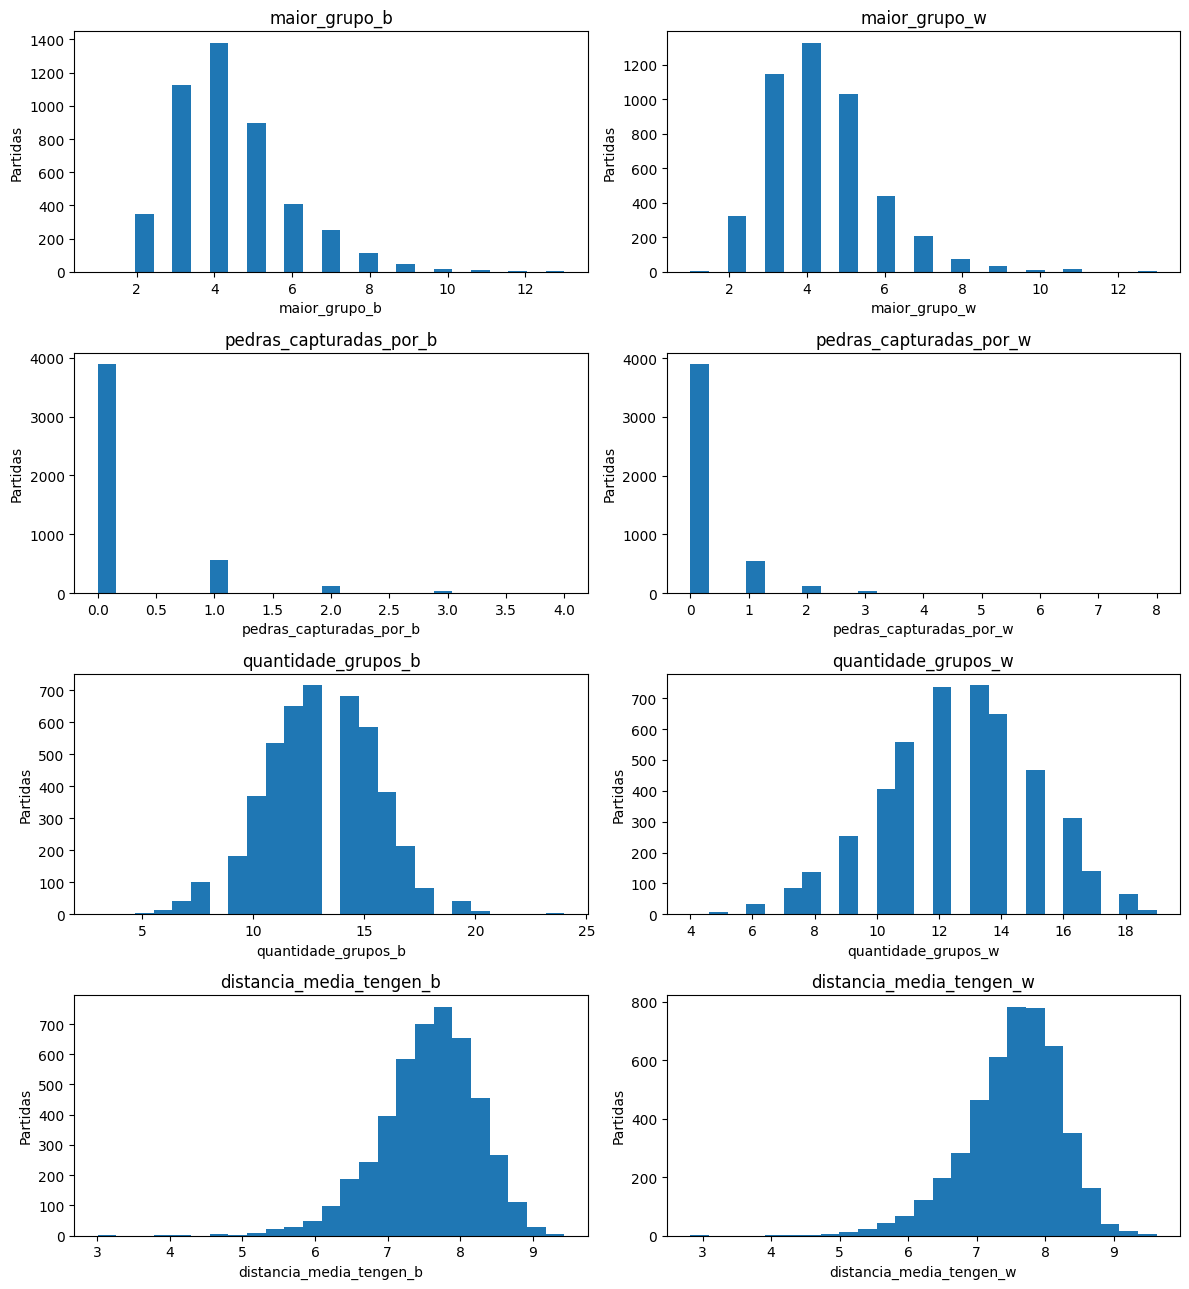

Fração com nenhuma captura por cada cor:
pedras_capturadas_por_b: 84.5%
pedras_capturadas_por_w: 84.5%


In [5]:
posicionais = ["maior_grupo_b", "maior_grupo_w", "pedras_capturadas_por_b",
               "pedras_capturadas_por_w", "quantidade_grupos_b", "quantidade_grupos_w",
               "distancia_media_tengen_b", "distancia_media_tengen_w"]
fig, axs = plt.subplots(4, 2, figsize=(12, 13))
for ax, c in zip(axs.flat, posicionais):
    ax.hist(train[c].dropna(), bins=25)
    ax.set(xlabel=c, ylabel="Partidas", title=c)
plt.tight_layout()
plt.show()
print("Fração com nenhuma captura por cada cor:")
for c in ["pedras_capturadas_por_b", "pedras_capturadas_por_w"]:
    print(f"{c}: {(train[c] == 0).mean():.1%}")

### Interpretação de outputs

Realizando uma analise dos atributos, existe uma baixa variância no atributo captura para ambas as cores, e para os demais atributos, os valores tem uma distribuição com variância moderada.

## 6. Redundância e correlação

Correlações entre atributos não demonstram causalidade. Elas podem, entretanto, indicar redundância e motivar uma investigação de seleção de atributos dentro da validação cruzada.

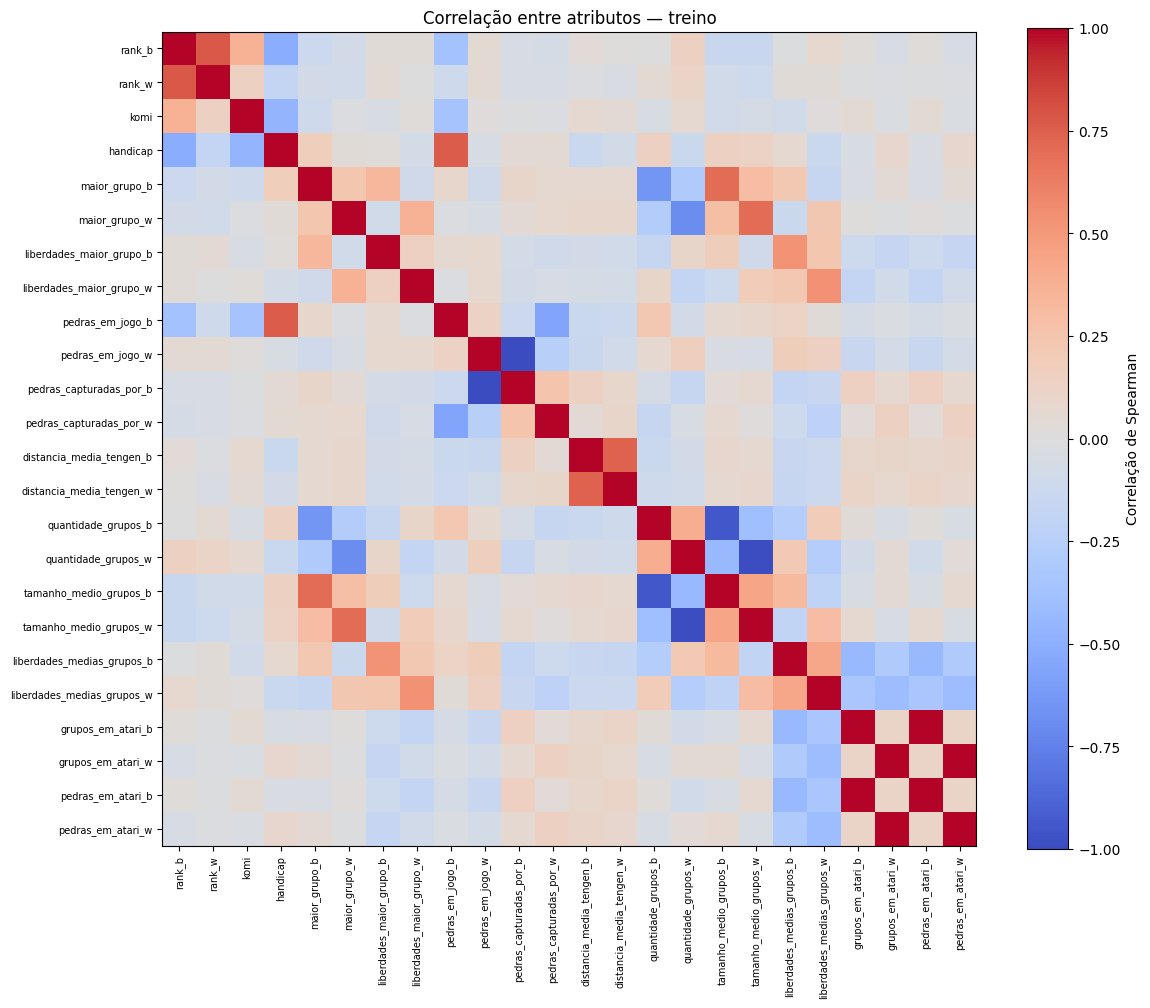

Pares com maior correlação absoluta:
pedras_em_jogo_w          pedras_capturadas_por_b     0.998650
grupos_em_atari_w         pedras_em_atari_w           0.997106
grupos_em_atari_b         pedras_em_atari_b           0.996452
quantidade_grupos_w       tamanho_medio_grupos_w      0.991438
quantidade_grupos_b       tamanho_medio_grupos_b      0.941866
rank_b                    rank_w                      0.780094
handicap                  pedras_em_jogo_b            0.763166
distancia_media_tengen_b  distancia_media_tengen_w    0.741453
maior_grupo_b             tamanho_medio_grupos_b      0.702644
maior_grupo_w             tamanho_medio_grupos_w      0.701138
                          quantidade_grupos_w         0.694831
maior_grupo_b             quantidade_grupos_b         0.644267


In [6]:
corr = train[ATRIBUTOS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
img = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(ATRIBUTOS)), ATRIBUTOS, rotation=90, fontsize=7)
ax.set_yticks(range(len(ATRIBUTOS)), ATRIBUTOS, fontsize=7)
fig.colorbar(img, ax=ax, label="Correlação de Spearman")
ax.set_title("Correlação entre atributos — treino")
plt.tight_layout()
plt.show()

pares = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("Pares com maior correlação absoluta:")
print(pares.head(12).to_string())

## 7. Valores extremos e critérios para a próxima etapa

Não vamos descartar observações apenas porque são extremas. Casos potencialmente impossíveis devem ser examinados nos SGFs originais.

In [7]:
print("Valores mínimos e máximos dos atributos:")
print(train[ATRIBUTOS].agg(["min", "max"]).T.to_string())
print("\nLinhas com komi ausente:", train["komi"].isna().sum())
print("Linhas com handicap ausente:", train["handicap"].isna().sum())

# Export opcional de resumo descritivo, sem acessar validação/teste.
resumo = train[ATRIBUTOS].describe().T
# Para salvar, descomente:
# Path("results").mkdir(exist_ok=True)
# resumo.to_csv("results/resumo_eda_treino_lance040.csv")

Valores mínimos e máximos dos atributos:
                                  min        max
rank_b                     -10.000000  15.000000
rank_w                      -4.000000  15.000000
komi                        -9.500000   8.000000
handicap                     0.000000   9.000000
maior_grupo_b                1.000000  13.000000
maior_grupo_w                1.000000  13.000000
liberdades_maior_grupo_b     1.000000  13.000000
liberdades_maior_grupo_w     1.000000  13.000000
pedras_em_jogo_b            12.000000  29.000000
pedras_em_jogo_w            16.000000  22.000000
pedras_capturadas_por_b      0.000000   4.000000
pedras_capturadas_por_w      0.000000   8.000000
distancia_media_tengen_b     3.009112   9.431497
distancia_media_tengen_w     2.818727   9.626195
quantidade_grupos_b          3.000000  24.000000
quantidade_grupos_w          4.000000  19.000000
tamanho_medio_grupos_b       1.000000   5.333333
tamanho_medio_grupos_w       1.000000   4.750000
liberdades_medias_grupos_b  

## 8. Próximos passos 

No notebook seguinte `02_baselines_preprocessamento_tiamat.ipynb` será feito a elaboração dos modelos de baselines e os piplines.

### Descrição do uso de IA neste trabalho

Foi realizado uma revisão do código desenvolvido pela IA, e foi realizado a modificação nas seções, pré estabelecidas em conjunto com a IA.

### Referências

- Joe's Go Database: https://www.pjreddie.com/projects/jgdb/
- Scikit-learn, Common pitfalls and recommended practices: https://scikit-learn.org/stable/common_pitfalls.html
- Contrato e enunciado da ATP-203 (arquivos fornecidos na disciplina).